# Unsupervised & Self-Supervised Learning on Materials

1. **Association rules** (Apriori) – which elements co-occur with stability, magnetism, metallicity, PV band gap.
2. **Clustering** – PCA + K-Means on labeled and unlabeled materials.
3. **Self-supervised pre-training** – masked-feature autoencoder on 554k GNoME compositions.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
U = ROOT / "data/predictions/unsupervised"
SS = ROOT / "data/predictions/self_supervised"
from IPython.display import Image, display

=== stability: 67 rules


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,"Er, Y",STABLE,0.0030,0.6582,2.2345,0.0017,2.0637
1,"Dy, Y",STABLE,0.0031,0.6484,2.2014,0.0017,2.0065
2,"La, Pr",STABLE,0.0031,0.6402,2.1735,0.0017,1.9606
3,"Sm, Y",STABLE,0.0030,0.6355,2.1574,0.0016,1.9351
4,"La, Nd",STABLE,0.0030,0.6348,2.1551,0.0016,1.9316
5,"Tb, Y",STABLE,0.0032,0.6326,2.1475,0.0017,1.9199
6,"Nd, Sm",STABLE,0.0030,0.6284,2.1333,0.0016,1.8982
7,"Tm, Y",STABLE,0.0027,0.6278,2.1313,0.0014,1.8951


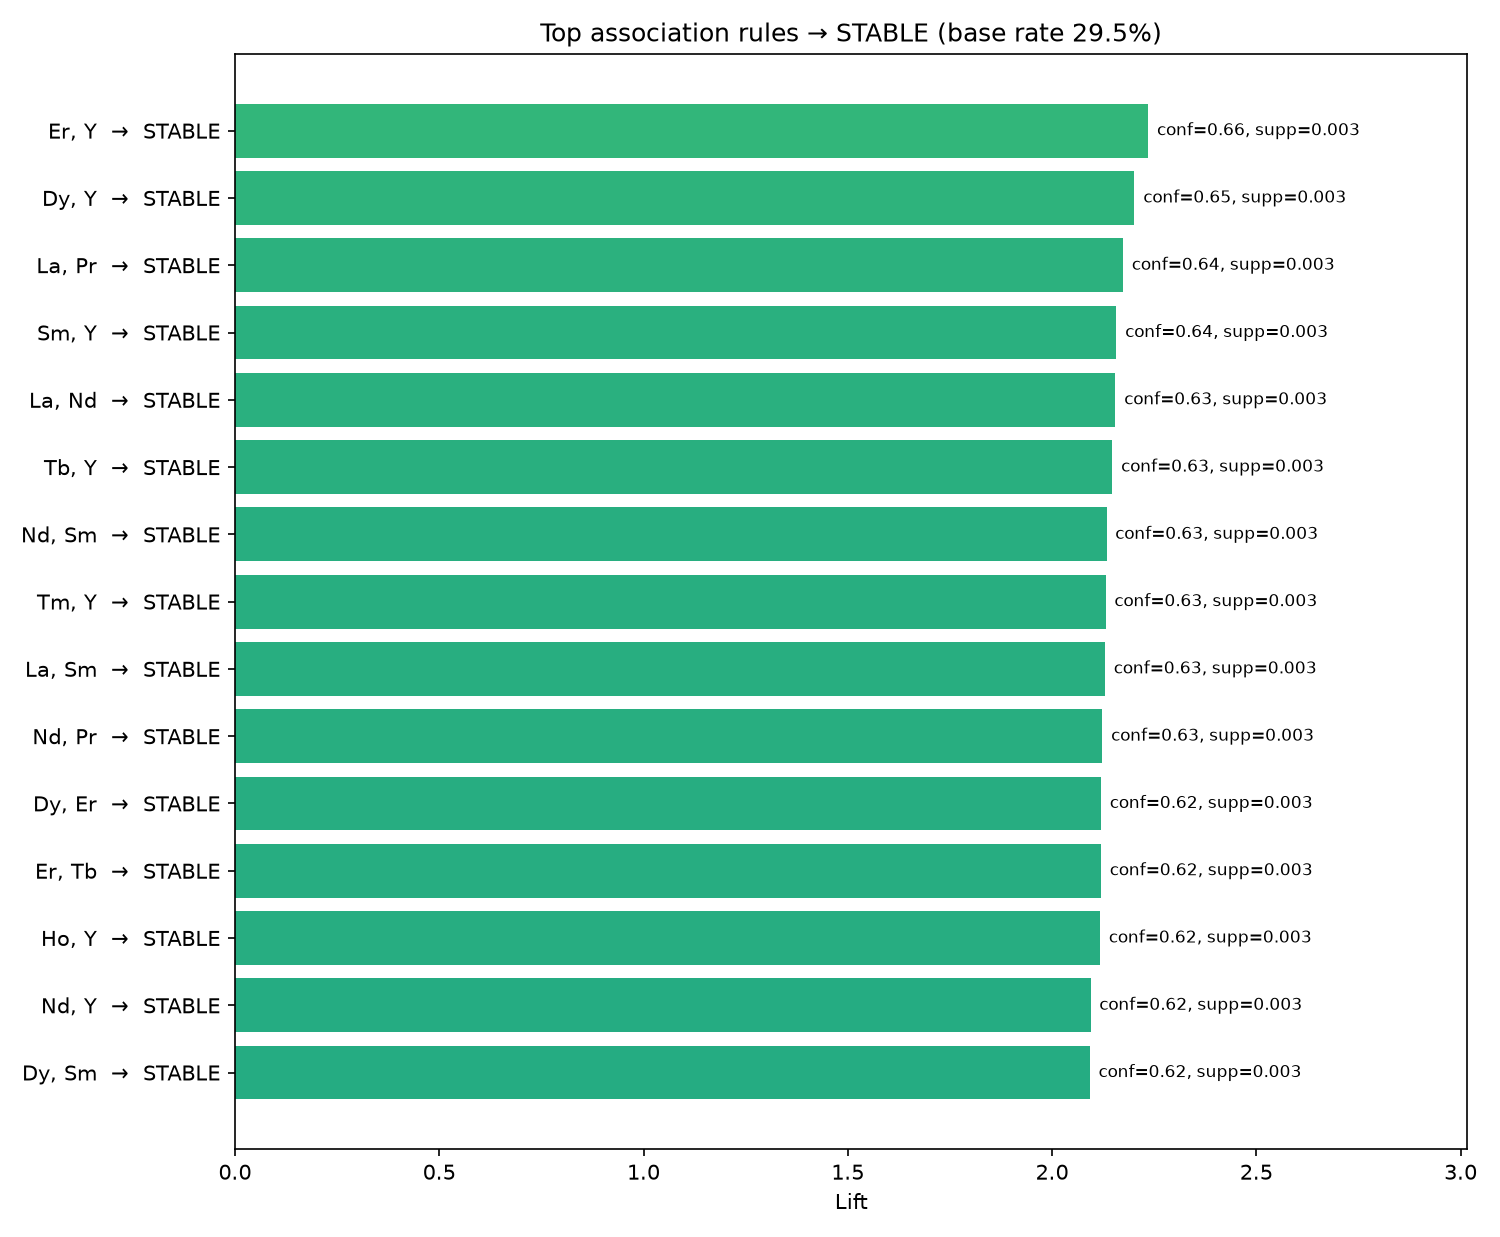

=== magnetism: 26 rules


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,"F, Mn",MAGNETIC,0.0035,0.9538,4.6354,0.0028,17.1845
1,"Mn, O",MAGNETIC,0.0193,0.9511,4.6222,0.0151,16.2323
2,"Li, Mn",MAGNETIC,0.0072,0.9486,4.6100,0.0056,15.4400
3,"Fe, Li",MAGNETIC,0.0063,0.9375,4.5563,0.0049,12.7078
4,"Cr, Li",MAGNETIC,0.0037,0.9219,4.4803,0.0028,10.1663
5,"Fe, O",MAGNETIC,0.0167,0.9059,4.4026,0.0129,8.4388
6,"Cr, O",MAGNETIC,0.0093,0.8467,4.1150,0.0071,5.1808
7,"Co, O",MAGNETIC,0.0122,0.8394,4.0793,0.0092,4.9443


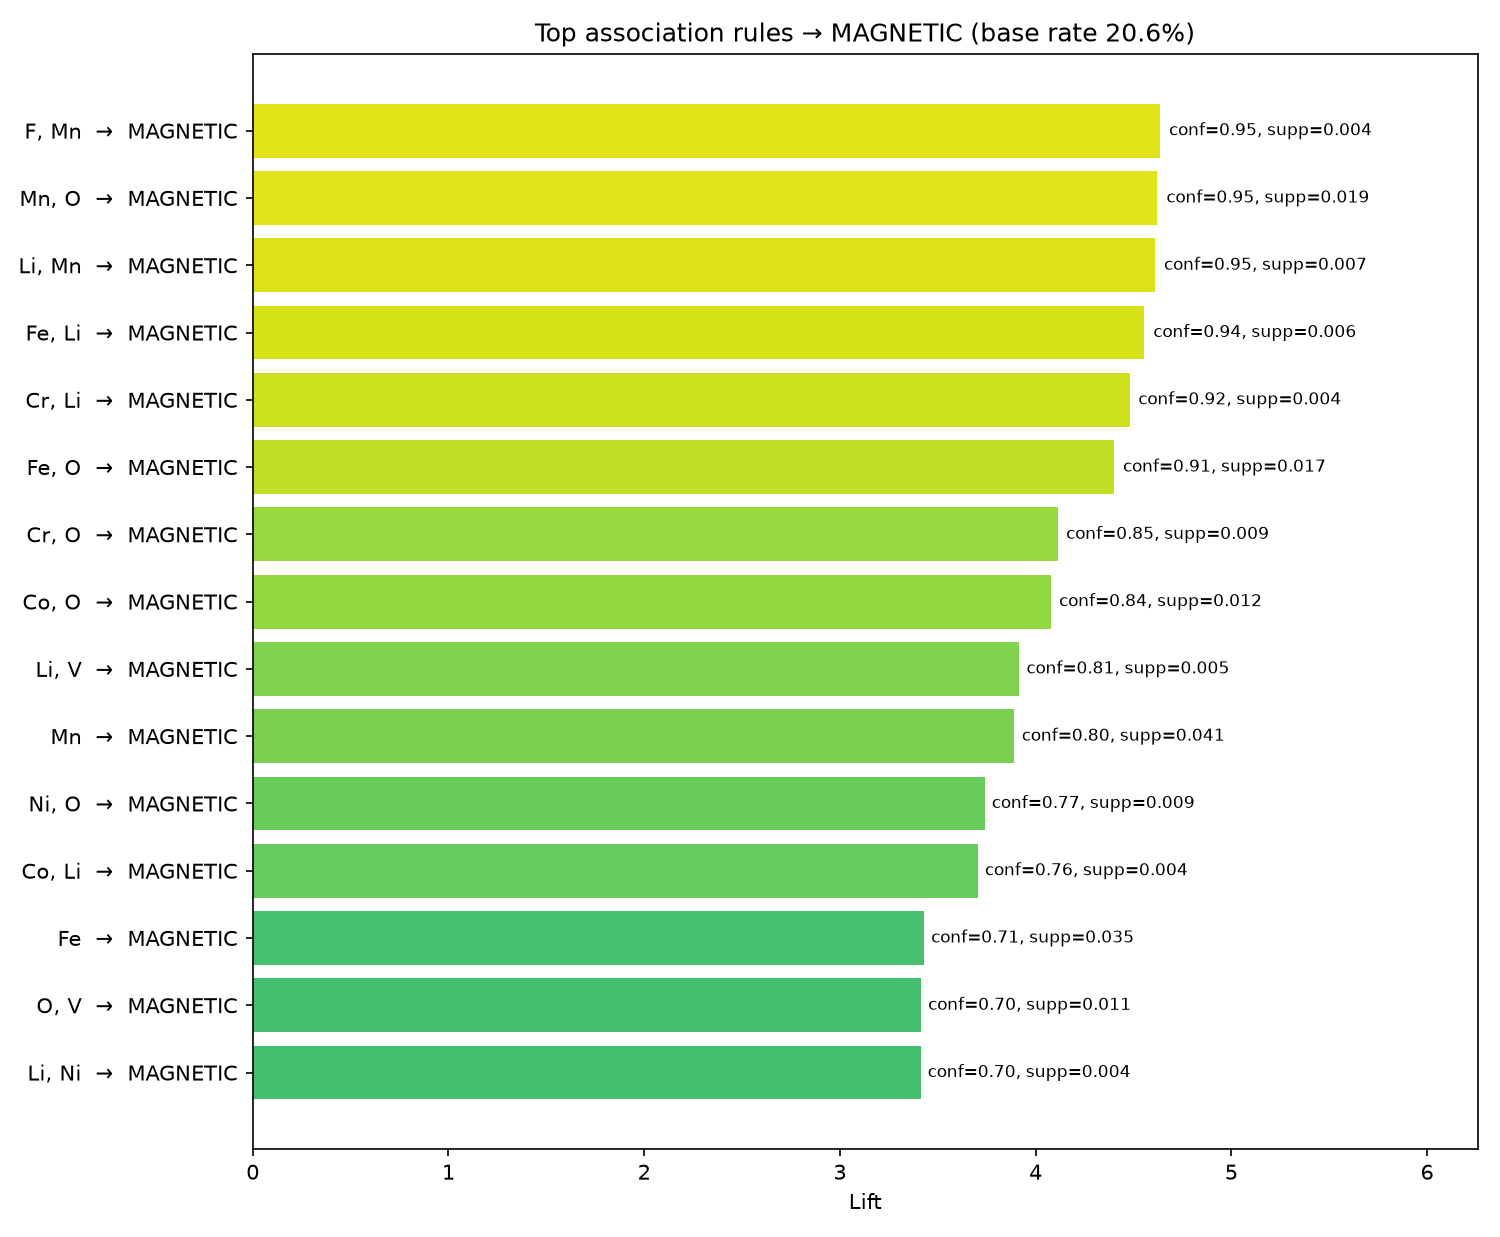

=== metallicity: 47 rules


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,Pm,METAL,0.0051,0.9681,2.0315,0.0026,16.4276
1,"Ga, Ni",METAL,0.0032,0.9326,1.9569,0.0016,7.7642
2,Ir,METAL,0.0166,0.8935,1.8749,0.0077,4.9161
3,"Al, Ni",METAL,0.0032,0.8869,1.8610,0.0015,4.6291
4,Rh,METAL,0.0213,0.8834,1.8536,0.0098,4.4875
5,Pd,METAL,0.0233,0.8330,1.7479,0.0100,3.1348
6,Os,METAL,0.0078,0.8294,1.7404,0.0033,3.0688
7,Ru,METAL,0.0183,0.8279,1.7371,0.0077,3.0409


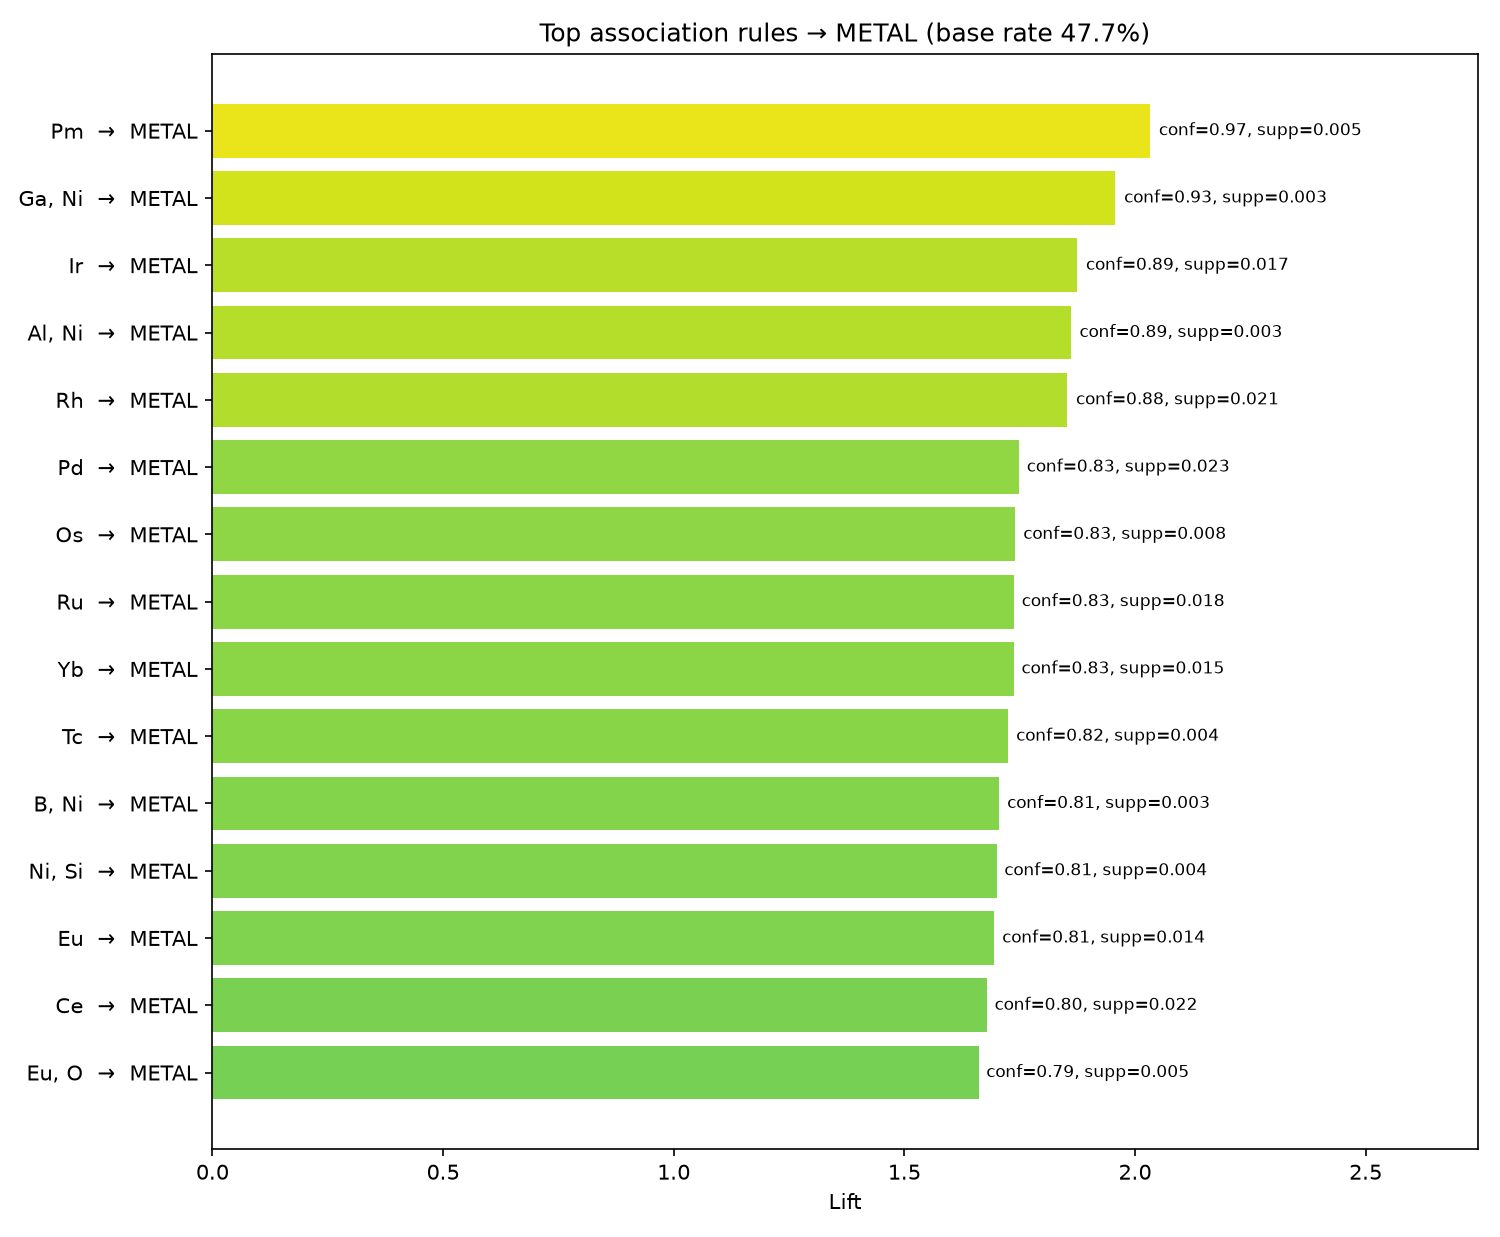

=== band_gap: 6 rules


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,Se,PV_GAP,0.0087,0.1789,2.6878,0.0054,1.1368
1,"O, V",PV_GAP,0.0060,0.1630,2.4485,0.0036,1.1152
2,"Fe, O",PV_GAP,0.0065,0.1444,2.1692,0.0035,1.0910
3,Br,PV_GAP,0.0035,0.1412,2.1205,0.0018,1.0868
4,S,PV_GAP,0.0113,0.1350,2.0288,0.0058,1.0792
5,V,PV_GAP,0.0067,0.1342,2.0159,0.0034,1.0781


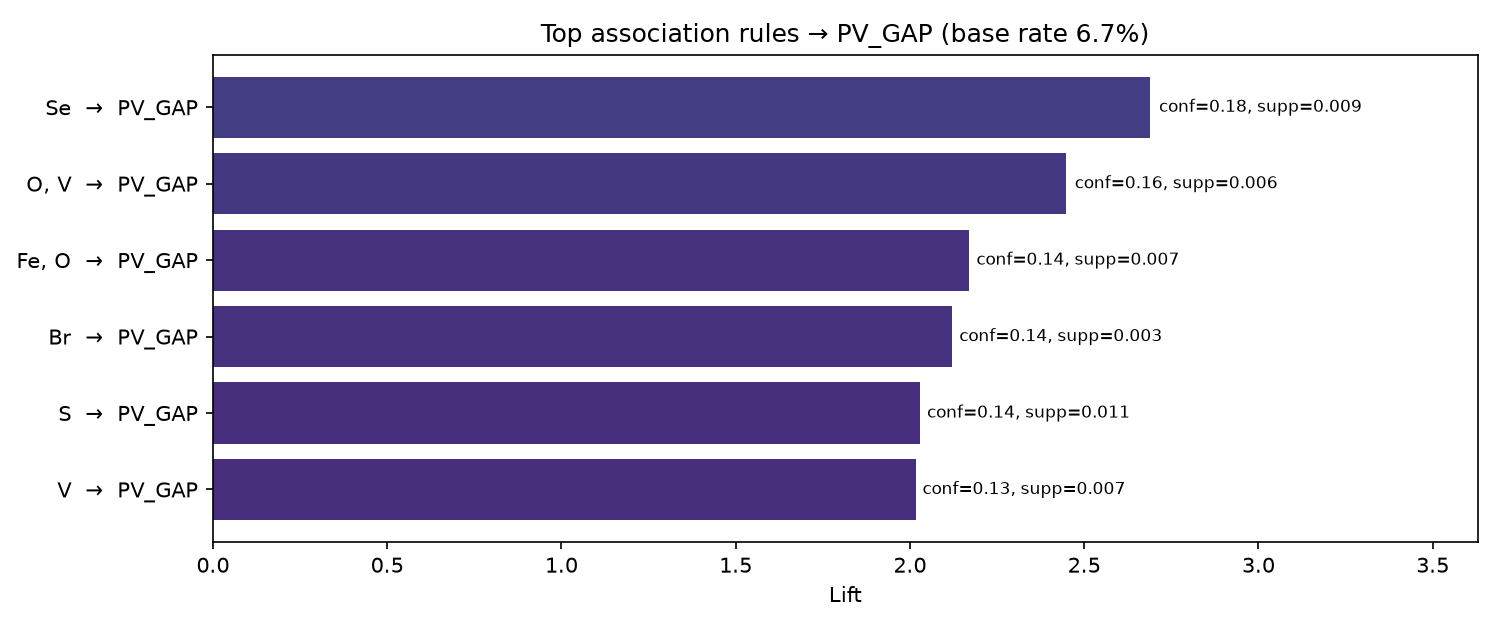

In [2]:
# 1. Association rules (support, confidence, lift)
for t in ['stability', 'magnetism', 'metallicity', 'band_gap']:
    r = pd.read_csv(U / f'association_rules_{t}.csv')
    print(f'=== {t}: {len(r)} rules'); display(r.head(8).round(4))
    display(Image(str(U / f'association_rules_{t}.png')))

In [3]:
# Element co-occurrence rules on the unlabeled GNoME database
display(pd.read_csv(U / 'association_rules_gnome_elements.csv').round(4))

,antecedents,consequents,support,confidence,lift
0,Hf,Zr,0.0105,0.2290,4.8921
1,Zr,Hf,0.0105,0.2242,4.8921
2,Co,P,0.0251,0.2267,2.9032
3,P,Co,0.0251,0.3215,2.9032
4,Pr,Nd,0.0166,0.2234,2.5141
5,Ti,Si,0.0123,0.3252,2.2594
6,Sc,Si,0.0197,0.3050,2.1194


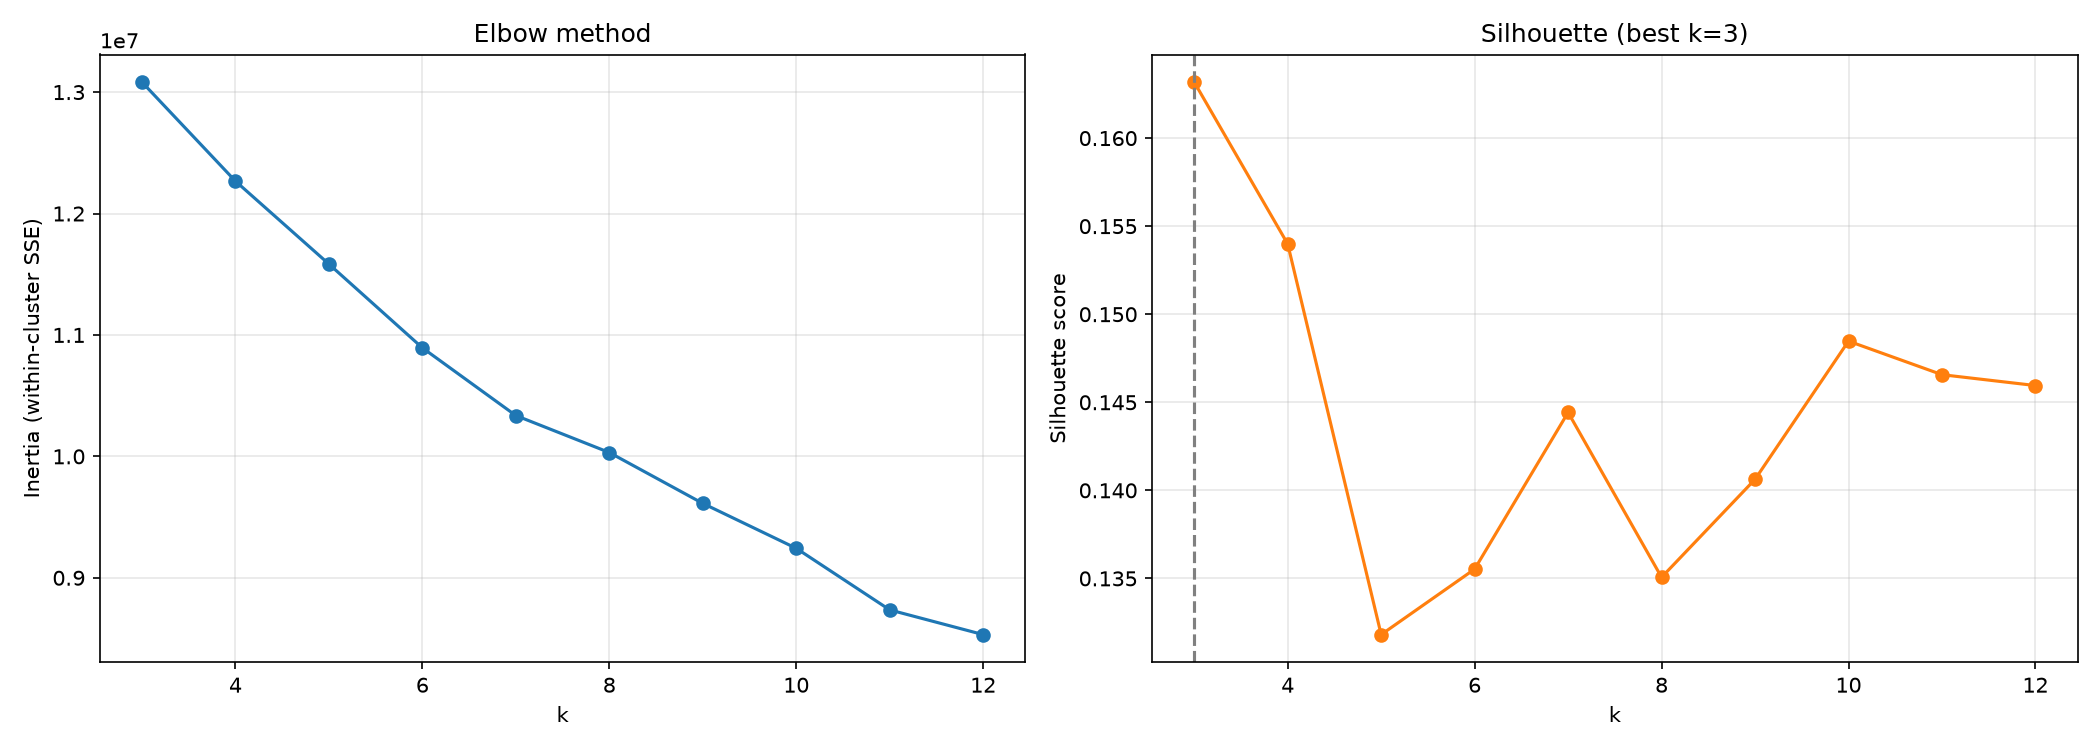

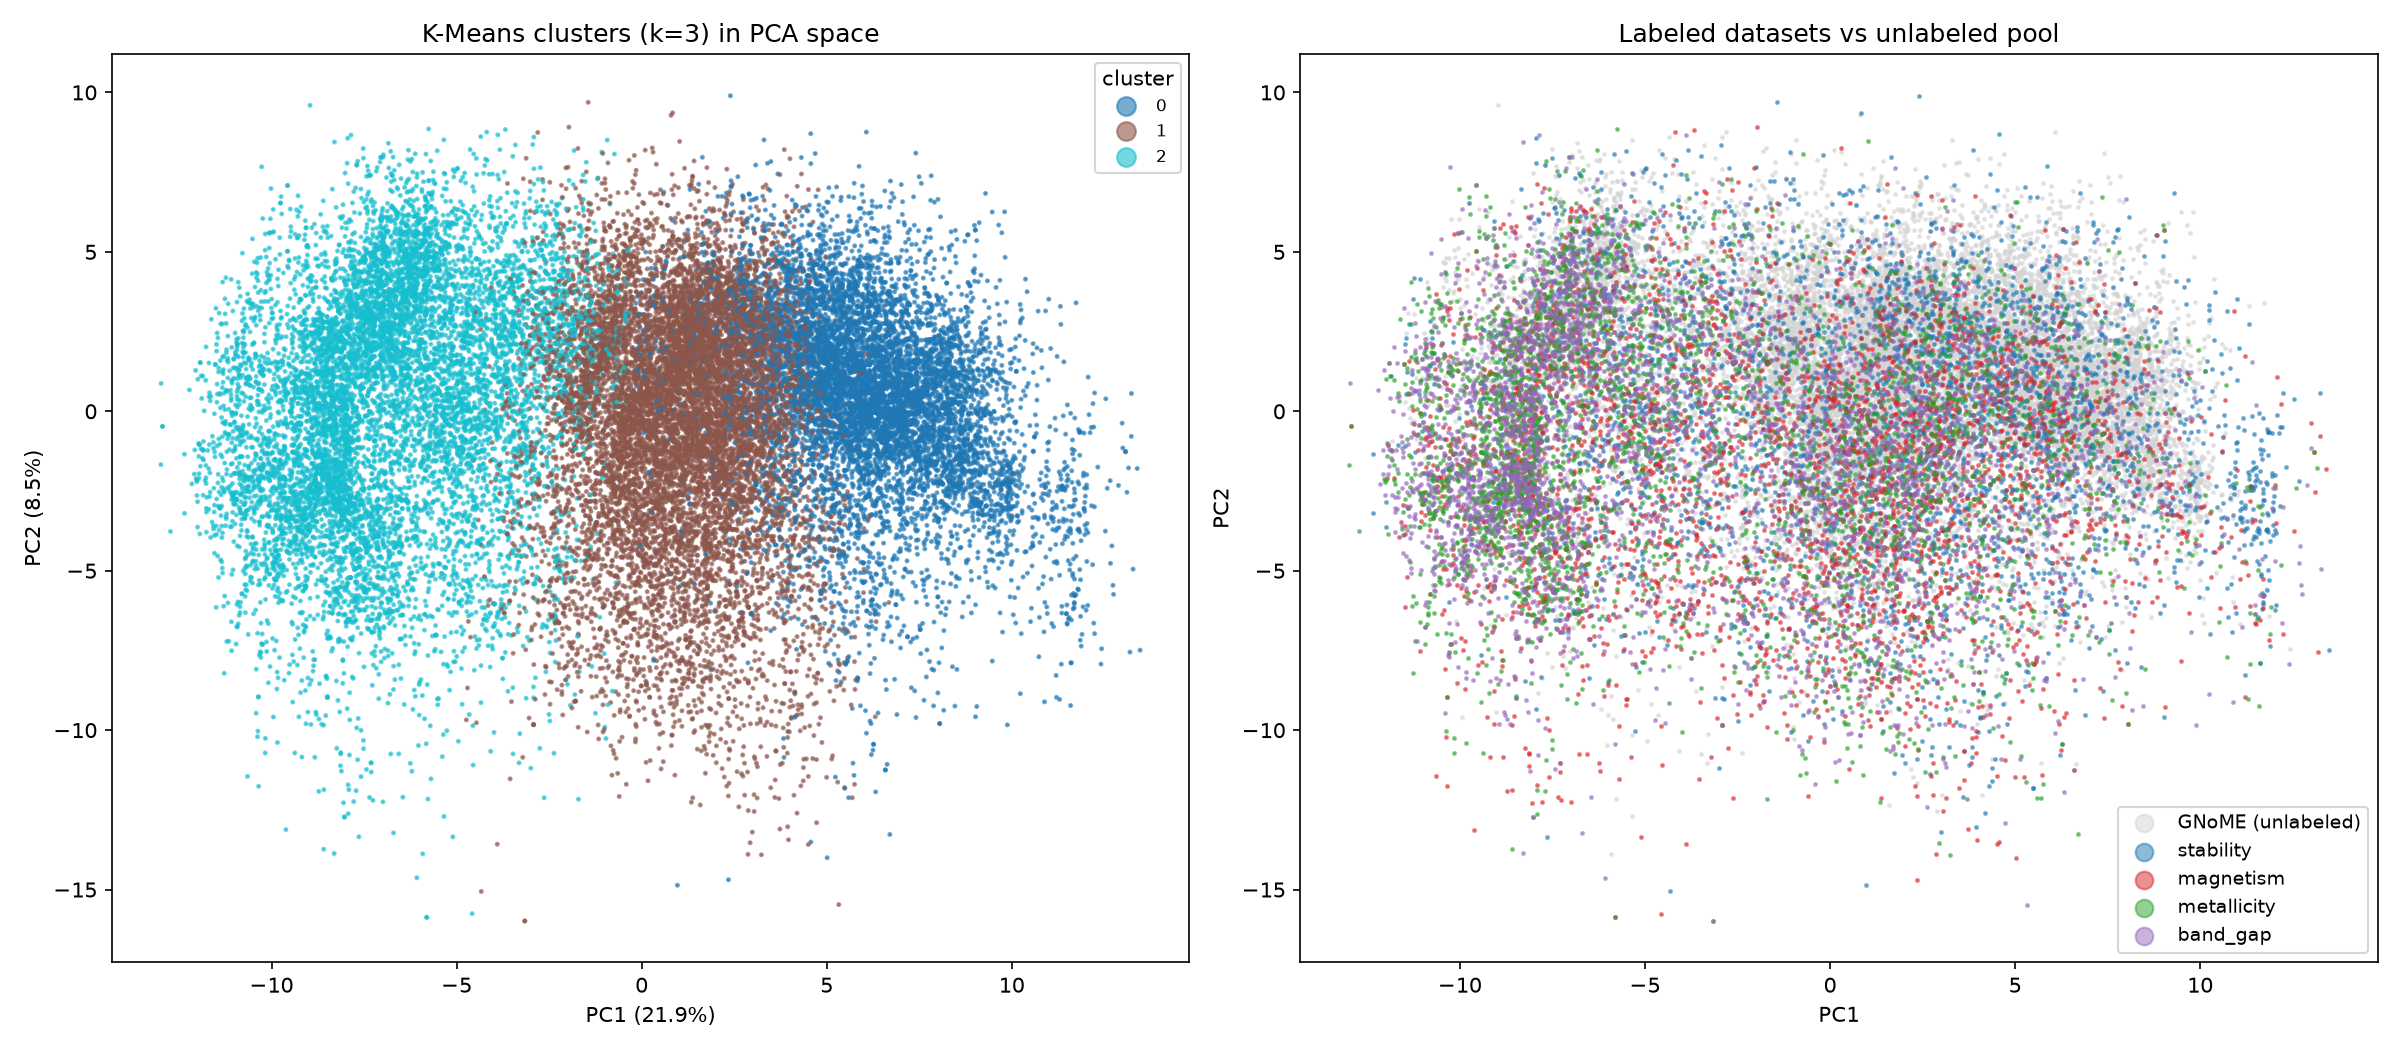

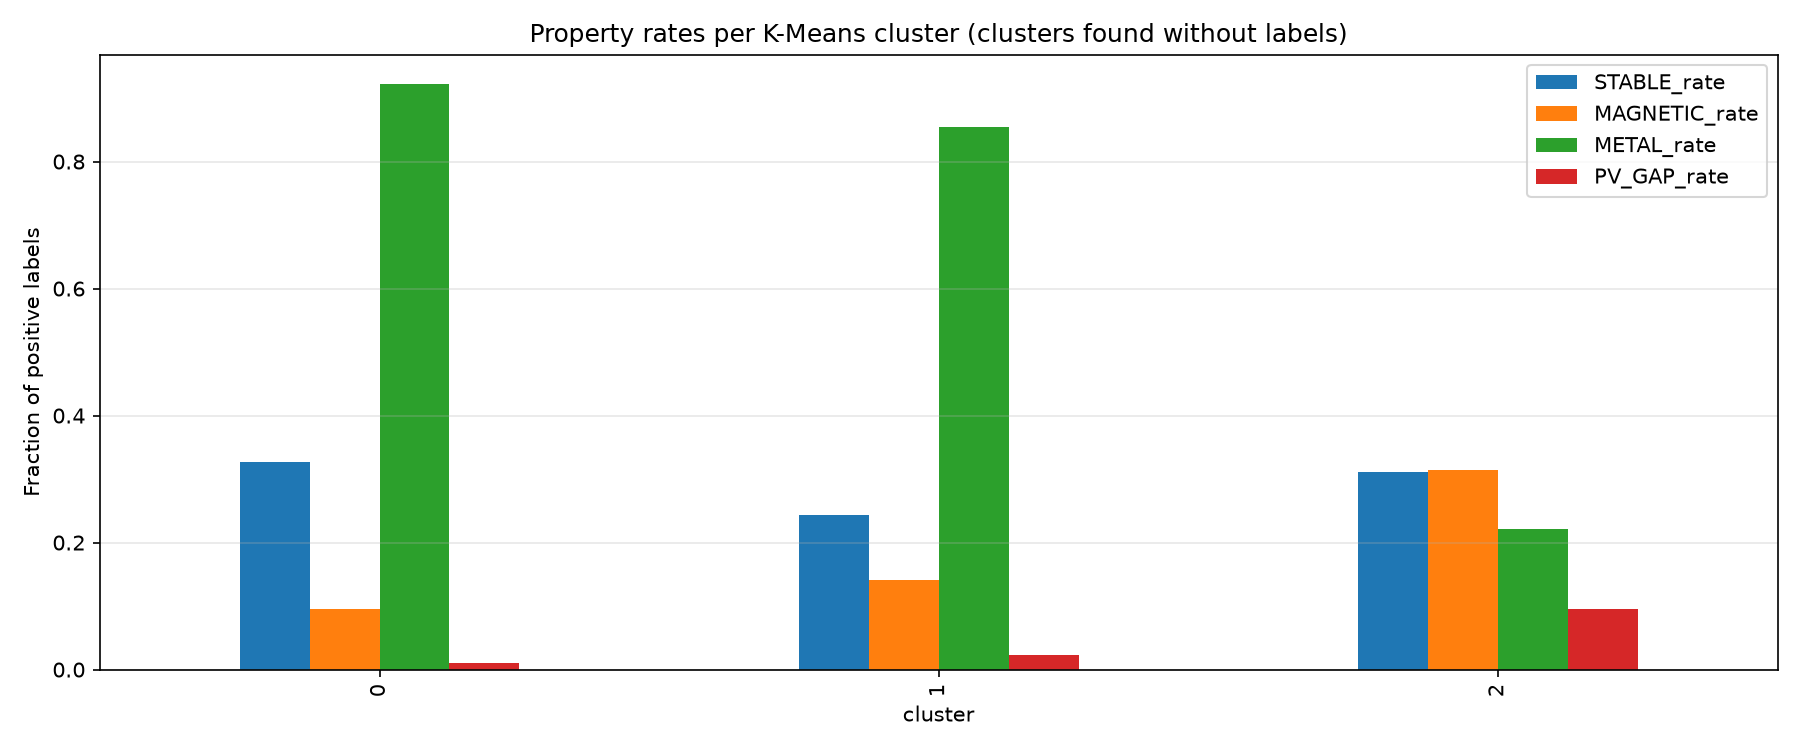

,cluster,size,share_gnome,mean_n_elements,STABLE_rate,MAGNETIC_rate,METAL_rate,PV_GAP_rate,top_elements
0,0,57462,0.652257,3.698462,0.326205,0.094795,0.922481,0.010555,"Ir (4%), Ho (4%), Dy (4%), Er (4%), Tb (4%)"
1,1,76947,0.581322,3.776028,0.243771,0.140459,0.854111,0.023694,"Si (5%), Al (4%), Co (3%), Ga (3%), B (3%)"
2,2,65591,0.271211,3.786998,0.311605,0.314381,0.221118,0.096083,"O (15%), F (3%), S (3%), Li (3%), P (3%)"


In [4]:
# 2. Clustering
for f in ('kmeans_elbow_silhouette.png', 'kmeans_pca_clusters.png', 'kmeans_cluster_property_rates.png'):
    display(Image(str(U / f)))
pd.read_csv(U / 'kmeans_cluster_profiles.csv')

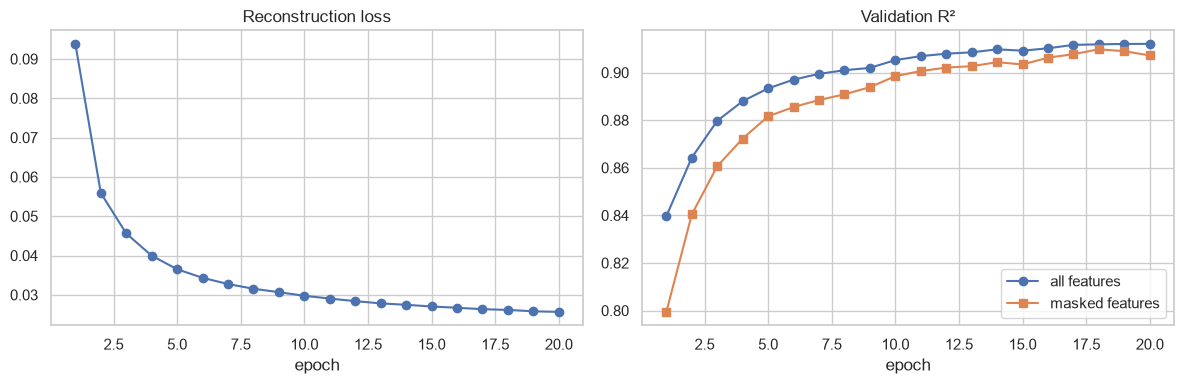

{'pretext_task': 'masked feature reconstruction (denoising autoencoder)',
 'n_unlabeled_samples': 554054,
 'architecture': [142, 128, 32, 128, 142],
 'embedding_dim': 32,
 'mask_rate': 0.25,
 'epochs': 20,
 'final': {'epoch': 20,
  'loss': 0.02566021887468486,
  'val_r2_all': 0.9120555520057678,
  'val_r2_masked_features': 0.9071837663650513}}

In [5]:
# 3. Self-supervised masked autoencoder
h = pd.read_csv(SS / 'autoencoder_training_history.csv')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.loss, 'o-'); ax[0].set(title='Reconstruction loss', xlabel='epoch')
ax[1].plot(h.epoch, h.val_r2_all, 'o-', label='all features')
ax[1].plot(h.epoch, h.val_r2_masked_features, 's-', label='masked features')
ax[1].set(title='Validation R²', xlabel='epoch'); ax[1].legend()
FIG = ROOT / 'report/figures/unsupervised'; FIG.mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig(FIG / 'autoencoder_training.png', dpi=150); plt.show()
json.loads((SS / 'autoencoder_summary.json').read_text())